# 06. Graph Community Detection & Echo Chamber Analysis

- **Role/Owner:** Member 3 (Analytics, Graph & Visualization Lead)
- **Core Responsibility:** Partition the users of the PHEME interaction network into communities with two different methods (Louvain and K-Means), and test whether false rumours concentrate in some communities and are pushed by a small group of repeat amplifiers (FR3).
- **Key Interface/Contract:** Consumes `backend/data/processed/pheme_interactions.csv.gz` (one row per tweet, built by `backend/scripts/extract_pheme_interactions.py`) and `backend/data/processed/cascade_features.csv`; outputs `backend/models/community_clusters.joblib`, `backend/data/processed/network_sample.json` (for `GET /api/cascades/network`) and `backend/reports/community_metrics.json`.

**Users, not tweets.** The graph file used in notebooks 01 and 02 (`pheme_political/pheme_cascades.gpickle`, from Hugging Face) has no user ids, so the first version of this notebook could only group cascades by their text. The raw PHEME veracity release (figshare 6392078, CC BY 4.0) has the author of every tweet and the user each reply answers. `extract_pheme_interactions.py` keeps those links with pseudonymous keys such as `u123` (no real ids, no text), so this notebook can build the user-user graph that FR3 asks for. The earlier cascade-level result is kept as an appendix (Section 11).

**What this notebook does**

1. Build the user interaction graph: one node per account, one edge per pair of accounts that replied to each other.
2. Method 1, Louvain: communities of users who talk to each other (community detection by modularity).
3. Method 2, K-Means: behavioural roles of users (how many threads they join, how much they reply and get replied to, followers, verified).
4. Compare the two methods with each other and with the news event.
5. Profile each community: users, main event, share of false-rumour participation, verified share, followers.
6. Test whether false-rumour participation concentrates in some communities more than the events alone explain.
7. Find repeat amplifiers (users who join three or more false threads) and test whether they are clustered and linked to each other.
8. Export the communities, a 300-user sample for the D3 network graph and a metrics report.

## 1. Setup

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import joblib
import sklearn
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
RESOLUTION = 1.0        # Louvain default resolution
N_PERM = 500            # shuffles per permutation test
MIN_FALSE_THREADS = 3   # a repeat amplifier joined at least this many false threads
MIN_USERS = 300         # communities shown in the profile tables
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").exists())
PROCESSED = ROOT / "backend" / "data" / "processed"
GRAPH_FILE = ROOT / "backend" / "data" / "pheme_political" / "pheme_cascades.gpickle"   # appendix only
MODELS = ROOT / "backend" / "models"
REPORTS = ROOT / "backend" / "reports"
MODELS.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)
print("repo root:", ROOT)

repo root: /Users/phaman/Documents/COS30048 - Inno/inno


## 2. Build the user interaction graph

Every reply in PHEME says which account it answers (`reply_to_user_key`). We link the replying account and the answered account with an undirected edge whose **weight** is the number of replies between them. Replies to oneself (a user continuing their own thread) are dropped. A reply whose target account never tweets in the dataset has no key and gives no edge.

The graph is analysed on its **largest connected component**: users outside it sit in tiny separate groups (often a single thread nobody else joined), where every method trivially returns that group.

In [2]:
tweets = pd.read_csv(PROCESSED / "pheme_interactions.csv.gz", dtype={"thread_id": str})
feat = pd.read_csv(PROCESSED / "cascade_features.csv", dtype={"cascade_id": str})
assert tweets["thread_id"].nunique() == len(feat) == 6425

replies = tweets.dropna(subset=["reply_to_user_key"])
replies = replies[replies["user_key"] != replies["reply_to_user_key"]]
pair_weight = replies.groupby(["user_key", "reply_to_user_key"]).size()

G = nx.Graph()
for (u, v), n in pair_weight.items():
    if G.has_edge(u, v):
        G[u][v]["weight"] += int(n)
    else:
        G.add_edge(u, v, weight=int(n))

components = sorted(nx.connected_components(G), key=len, reverse=True)
H = G.subgraph(components[0]).copy()
users = sorted(H)                                      # fixed order for every array below
print(f"{tweets['user_key'].nunique():,} users tweet in PHEME; {G.number_of_nodes():,} have at least one reply link")
print(f"{len(components):,} connected components; largest {H.number_of_nodes():,} users "
      f"({H.number_of_nodes() / G.number_of_nodes():.1%}), {H.number_of_edges():,} edges; second largest {len(components[1])}")

50,593 users tweet in PHEME; 50,041 have at least one reply link
381 connected components; largest 47,833 users (95.6%), 61,942 edges; second largest 47


## 3. Participation and veracity

A **participation** is one user taking part in one thread (as author or replier). Each thread has a veracity:

- `mis = 1` for rumours annotated **false**, `mis = 0` for **true** rumours and **non-rumours**, and `mis = NaN` for **unverified** rumours (their truth is unknown, so they are left out of every rate below).
- `prince-toronto` and `ebola-essien` are almost entirely false (98%), so the event alone would decide the label. As in the text models, the rates and tests use the other events only (`main_event`).

A user's **false share** is the share of their participations (main events, known veracity) that are in false threads. The labels are never used to build the communities, only to describe them afterwards.

In [3]:
thread_info = feat.set_index("cascade_id")[["event", "veracity"]].copy()
thread_info["mis"] = thread_info["veracity"].map({"false": 1.0, "true": 0.0, "non-rumour": 0.0})
thread_info["main_event"] = ~thread_info["event"].str.contains("prince|ebola")
thread_info["event_short"] = thread_info["event"].str.replace("-all-rnr-threads", "", regex=False)

part = tweets[["user_key", "thread_id"]].drop_duplicates().join(thread_info, on="thread_id")
part = part[part["user_key"].isin(H.nodes)]
known = part[part["main_event"] & part["mis"].notna()].copy()
print(f"participations in the component: {len(part):,}; main events with known veracity: {len(known):,}")
print(f"false share of those participations: {known['mis'].mean():.3f}")

user_event = part.groupby("user_key")["event_short"].agg(lambda s: s.value_counts().index[0]).reindex(users)
print("users per main event:", user_event.value_counts().to_dict())

participations in the component: 66,350; main events with known veracity: 58,509
false share of those participations: 0.064


users per main event: {'charliehebdo': 16699, 'sydneysiege': 10952, 'ferguson': 10421, 'ottawashooting': 6706, 'germanwings-crash': 2242, 'prince-toronto': 353, 'putinmissing': 301, 'ebola-essien': 132, 'gurlitt': 27}


## 4. Method 1: Louvain on the user graph

Louvain finds communities by maximising **modularity** (how much more strongly users are connected inside their community than expected by chance; values above about 0.3 are usually read as real community structure). The `resolution` setting trades few large communities (low values) against many small ones (high values). The table shows the effect and how much each partition just follows the users' main event; the standard value 1.0 is used for the main analysis. Communities are numbered by size (0 = largest), so the numbers are the same on every machine.

In [4]:
def louvain_labels(graph, resolution):
    comms = sorted(nx.community.louvain_communities(graph, weight="weight", resolution=resolution, seed=SEED),
                   key=lambda c: (-len(c), min(c)))
    lab = pd.Series({u: i for i, c in enumerate(comms) for u in c}).reindex(users).to_numpy()
    q = nx.community.modularity(graph, comms, weight="weight", resolution=resolution)
    return lab, float(q), len(comms)


rows = []
for res in [0.5, 1.0, 2.0]:
    lab, q, n = louvain_labels(H, res)
    rows.append({"resolution": res, "communities": n, "modularity": q,
                 "ARI vs main event": adjusted_rand_score(user_event, lab)})
res_table = pd.DataFrame(rows).round(3)
res_table

,resolution,communities,modularity,ARI vs main event
0,0.5,85,0.883,0.138
1,1.0,143,0.871,0.043
2,2.0,238,0.862,0.021


In [5]:
louvain, Q, n_comm = louvain_labels(H, RESOLUTION)
louvain_of = pd.Series(louvain, index=users)
sizes = louvain_of.value_counts()
print(f"Louvain (resolution {RESOLUTION}): {n_comm} communities, modularity Q = {Q:.3f}")
print(f"communities with >= {MIN_USERS} users: {(sizes >= MIN_USERS).sum()}, holding {sizes[sizes >= MIN_USERS].sum() / len(users):.0%} of users")
print("largest communities:", sizes.head(8).to_dict())

Louvain (resolution 1.0): 143 communities, modularity Q = 0.871
communities with >= 300 users: 51, holding 67% of users
largest communities: {0: 2745, 1: 1418, 2: 1252, 3: 1147, 4: 1111, 5: 1060, 6: 1034, 7: 1033}


## 5. Method 2: K-Means on user behaviour

K-Means needs points in a feature space, not a graph, so it describes users by **how** they take part instead of **who** they talk to:

| Feature | Meaning |
|---|---|
| `threads` | distinct threads joined |
| `replies_sent`, `replies_received` | reply links to and from other users |
| `followers` | median follower count over the user's tweets |
| `sources` | threads the user started |
| `verified` | verified badge on any tweet |

Counts are log-transformed and every feature is standardised. `k` is chosen from 3 to 8 by the **silhouette score** (how well each point fits its own cluster compared with the nearest other cluster; higher is better), on a fixed sample of 5,000 users. Clusters are numbered by size.

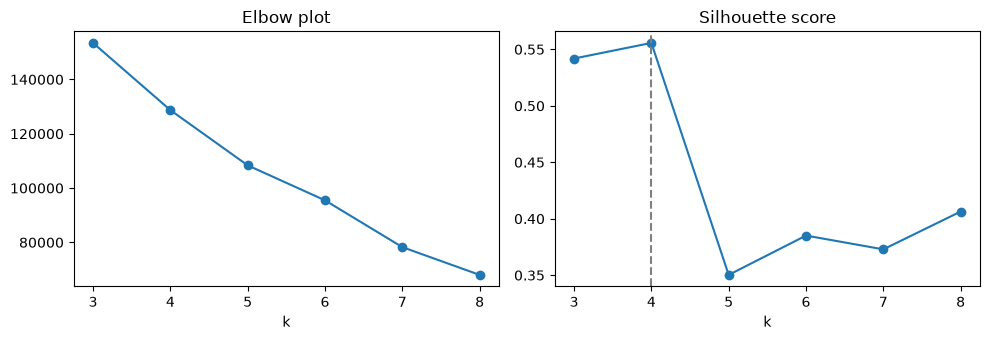

chosen k: 4


,k,inertia,silhouette
0,3,153430.7516,0.5419
1,4,128691.5365,0.5557
2,5,108357.9918,0.3503
3,6,95476.9344,0.3851
4,7,78249.2741,0.3729
5,8,68026.5136,0.4064


In [6]:
tw_c = tweets[tweets["user_key"].isin(H.nodes)]
behaviour = pd.DataFrame({
    "threads": tw_c.groupby("user_key")["thread_id"].nunique(),
    "replies_sent": replies.groupby("user_key").size(),
    "replies_received": replies.groupby("reply_to_user_key").size(),
    "followers": tw_c.groupby("user_key")["user_followers"].median(),
    "sources": tw_c.groupby("user_key")["is_source"].sum(),
    "verified": tw_c.groupby("user_key")["user_verified"].max(),
}).reindex(users).fillna(0)
LOG_COLS = ["threads", "replies_sent", "replies_received", "followers", "sources"]
X = np.column_stack([np.log1p(behaviour[c]) for c in LOG_COLS] + [behaviour["verified"]])
scaler = StandardScaler().fit(X)
Xs = scaler.transform(X)

rows = []
for k in range(3, 9):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
    rows.append({"k": k, "inertia": float(km_k.inertia_),
                 "silhouette": float(silhouette_score(Xs, km_k.labels_, sample_size=5000, random_state=SEED))})
k_table = pd.DataFrame(rows)
best_k = int(k_table.sort_values("silhouette", ascending=False).iloc[0]["k"])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(k_table["k"], k_table["inertia"], marker="o"); ax[0].set_title("Elbow plot")
ax[1].plot(k_table["k"], k_table["silhouette"], marker="o"); ax[1].axvline(best_k, linestyle="--", color="gray")
ax[1].set_title("Silhouette score")
for a in ax:
    a.set_xlabel("k")
plt.tight_layout(); plt.show()

km = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(Xs)
order = pd.Series(km.labels_).value_counts().index            # cluster ids by size, largest first
remap = {old: new for new, old in enumerate(order)}
kmeans = np.array([remap[c] for c in km.labels_])
print("chosen k:", best_k)
k_table.round(4)

In [7]:
roles = behaviour.assign(cluster=kmeans).groupby("cluster").agg(
    users=("threads", "size"), median_threads=("threads", "median"), median_sent=("replies_sent", "median"),
    median_received=("replies_received", "median"), median_followers=("followers", "median"),
    sources_mean=("sources", "mean"), verified_share=("verified", "mean"))
roles.round(2)

,users,median_threads,median_sent,median_received,median_followers,sources_mean,verified_share
cluster,,,,,,,
0,39235,1.0,1.0,0.0,287.0,0.00,0.0
1,6032,2.0,5.0,3.0,472.0,0.01,0.0
2,1344,1.0,0.0,11.0,6922.5,1.74,0.0
3,1222,1.0,0.0,8.0,33750.0,2.63,1.0


## 6. How do the two methods compare, and do they just recover the news event?

- **ARI** (adjusted Rand index) and **NMI** (normalised mutual information) measure how similar two groupings are: 1 means identical, 0 means no more similar than random.
- A high ARI with the user's main event would mean a method mostly rediscovered which news story the users talked about.

In [8]:
pairs = {
    "Louvain vs K-Means": (louvain, kmeans),
    "Louvain vs main event": (louvain, user_event),
    "K-Means vs main event": (kmeans, user_event),
}
compare = pd.DataFrame({name: {"ARI": adjusted_rand_score(a, b), "NMI": normalized_mutual_info_score(a, b)}
                        for name, (a, b) in pairs.items()}).T.round(3)
compare

,ARI,NMI
Louvain vs K-Means,0.001,0.007
Louvain vs main event,0.043,0.230
K-Means vs main event,-0.004,0.006


## 7. Profile of each community

`false_share` is the share of the community's participations (main events, known veracity) that are in false threads, `event_purity` the share of its participations in its most common event. Communities with at least 300 users are shown; the bar chart ranks them by false share.

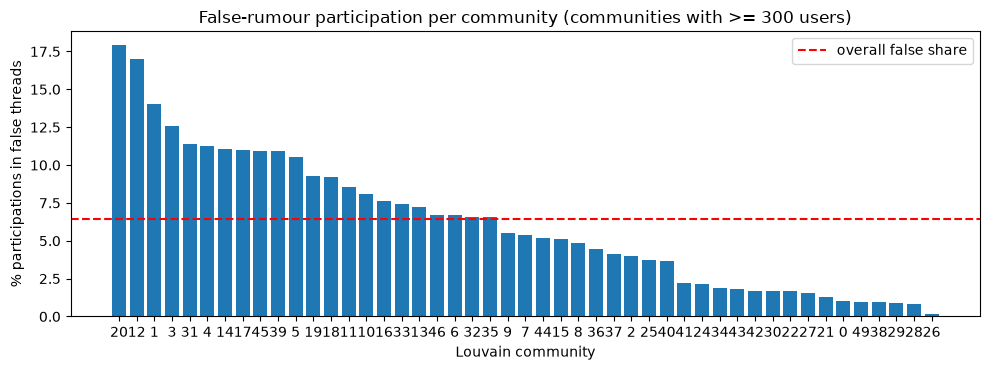

,users,participations,false_share,top_event,event_purity,verified_share,median_followers
louvain,,,,,,,
20,528,697,0.179,sydneysiege,0.651,0.009,450.00
12,650,940,0.170,charliehebdo,0.434,0.020,242.50
1,1248,1798,0.140,sydneysiege,0.384,0.022,223.50
3,981,1413,0.126,charliehebdo,0.665,0.044,363.00
31,325,430,0.114,charliehebdo,0.326,0.018,181.00
4,958,1322,0.113,charliehebdo,0.619,0.015,239.00
14,716,931,0.111,ottawashooting,0.838,0.041,315.00
17,654,907,0.110,sydneysiege,0.852,0.035,243.50
45,329,430,0.109,charliehebdo,0.788,0.015,411.00


In [9]:
known["louvain"] = known["user_key"].map(louvain_of)
user_verified = behaviour["verified"]
user_followers = behaviour["followers"]


def profile(d, col):
    g = d.groupby(col)
    members = d.groupby(col)["user_key"].unique()
    return pd.DataFrame({
        "users": g["user_key"].nunique(),
        "participations": g.size(),
        "false_share": g["mis"].mean(),
        "top_event": g["event_short"].agg(lambda s: s.value_counts().index[0]),
        "event_purity": g["event_short"].agg(lambda s: s.value_counts(normalize=True).iloc[0]),
        "verified_share": members.map(lambda m: user_verified[m].mean()),
        "median_followers": members.map(lambda m: user_followers[m].median()),
    })


louvain_profile = profile(known, "louvain")
louvain_shown = louvain_profile[louvain_profile["users"] >= MIN_USERS].sort_values("false_share", ascending=False)
overall_false = known["mis"].mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(louvain_shown.index.astype(str), louvain_shown["false_share"] * 100)
ax.axhline(overall_false * 100, color="red", linestyle="--", label="overall false share")
ax.set_xlabel("Louvain community"); ax.set_ylabel("% participations in false threads")
ax.set_title(f"False-rumour participation per community (communities with >= {MIN_USERS} users)")
ax.legend(); plt.tight_layout(); plt.show()
louvain_shown.round(3)

In [10]:
known["kmeans"] = known["user_key"].map(pd.Series(kmeans, index=users))
kmeans_profile = profile(known, "kmeans")
kmeans_profile.round(3)

,users,participations,false_share,top_event,event_purity,verified_share,median_followers
kmeans,,,,,,,
0,35010,37582,0.065,charliehebdo,0.370,0.0,284.00
1,5779,15203,0.059,charliehebdo,0.403,0.0,481.00
2,1224,2300,0.063,charliehebdo,0.373,0.0,7387.75
3,1145,3424,0.081,charliehebdo,0.358,1.0,36324.00


## 8. Does false-rumour participation concentrate in some communities?

**Cramer's V** (0 = no link, 1 = perfect link) between the community and "the thread is false", over all participations. Two comparisons:

1. The same V for the plain event grouping. If communities were only events, V would be similar.
2. A **permutation test** that shuffles the veracity labels between threads **of the same event**. This keeps every event's false rate and every user's activity, and removes any link between who talks to whom and which threads are false. The observed V should be above most shuffled values to claim that communities matter beyond the event.

The thread is the unit that is shuffled, because all users in one thread share its label.

In [11]:
def cramers_v(groups, labels):
    ct = pd.crosstab(groups, labels)
    return float(np.sqrt(chi2_contingency(ct)[0] / ct.values.sum()))


threads_k, thread_pos = np.unique(known["thread_id"].to_numpy(), return_inverse=True)
thread_mis = thread_info.loc[threads_k, "mis"].to_numpy()
thread_groups = pd.Series(np.arange(len(threads_k))).groupby(thread_info.loc[threads_k, "event"].to_numpy()).indices
rng = np.random.default_rng(SEED)


def shuffled_thread_labels():
    b = thread_mis.copy()
    for pos in thread_groups.values():
        b[pos] = rng.permutation(b[pos])
    return b


v_louvain = cramers_v(known["louvain"], known["mis"])
v_kmeans = cramers_v(known["kmeans"], known["mis"])
v_event = cramers_v(known["event"], known["mis"])
null_v = np.array([cramers_v(known["louvain"].to_numpy(), shuffled_thread_labels()[thread_pos]) for _ in range(N_PERM)])
p_v = float((np.sum(null_v >= v_louvain) + 1) / (N_PERM + 1))
print(f"Cramer's V with 'false': Louvain {v_louvain:.3f} | K-Means {v_kmeans:.3f} | event only {v_event:.3f}")
print(f"within-event shuffles: mean {null_v.mean():.3f}, max {null_v.max():.3f}, p = {p_v:.4f}")

Cramer's V with 'false': Louvain 0.226 | K-Means 0.020 | event only 0.199
within-event shuffles: mean 0.191, max 0.229, p = 0.0080


## 9. Repeat amplifiers: is there coordinated amplification?

A **repeat amplifier** is a user who took part in at least three different false threads. If false rumours were pushed by a coordinated group, these users would (a) gather in a few communities and (b) reply to each other more than chance.

The null model is again the within-event shuffle of thread labels: it keeps every user's activity and the graph as they are, so busy users can still become "amplifiers" by chance. For each shuffle we recompute who the amplifiers are and count the edges among them.

In [12]:
u_index = pd.Series(np.arange(len(users)), index=users)
part_user = u_index[known["user_key"]].to_numpy()
edge_u = u_index[[u for u, _ in H.edges()]].to_numpy()
edge_v = u_index[[v for _, v in H.edges()]].to_numpy()


def amplifier_mask(labels_per_part):
    false_threads = np.bincount(part_user, weights=labels_per_part, minlength=len(users))   # one row per user-thread
    return false_threads >= MIN_FALSE_THREADS


def edges_among(mask):
    return int(np.sum(mask[edge_u] & mask[edge_v]))


def top5_share(mask):
    """Share of the amplifiers that sit in the 5 communities holding the most of them."""
    counts = np.bincount(louvain[mask], minlength=n_comm)
    return float(np.sort(counts)[-5:].sum() / max(mask.sum(), 1))


amp = amplifier_mask(known["mis"].to_numpy())
obs_amp, obs_edges, obs_top5 = int(amp.sum()), edges_among(amp), top5_share(amp)
null_amp, null_edges, null_top5 = [], [], []
for _ in range(N_PERM):
    m = amplifier_mask(shuffled_thread_labels()[thread_pos])
    null_amp.append(int(m.sum())); null_edges.append(edges_among(m)); null_top5.append(top5_share(m))
null_amp, null_edges, null_top5 = np.array(null_amp), np.array(null_edges), np.array(null_top5)
p_amp = float((np.sum(null_amp >= obs_amp) + 1) / (N_PERM + 1))
p_edges = float((np.sum(null_edges >= obs_edges) + 1) / (N_PERM + 1))
p_top5 = float((np.sum(null_top5 >= obs_top5) + 1) / (N_PERM + 1))

amp_comm = louvain_of[np.array(users)[amp]].value_counts()
top5 = amp_comm.head(5)
top5_user_share = sizes[top5.index].sum() / len(users)
print(f"repeat amplifiers: {obs_amp} (within-event shuffles: mean {null_amp.mean():.1f}, p = {p_amp:.4f})")
print(f"edges among them: {obs_edges} (shuffles: mean {null_edges.mean():.1f}, max {null_edges.max()}, p = {p_edges:.4f})")
print(f"the 5 communities with most amplifiers hold {obs_top5:.0%} of them and {top5_user_share:.0%} of users "
      f"(shuffles: mean {null_top5.mean():.0%}, p = {p_top5:.4f})")
amp_table = pd.DataFrame({"amplifiers": top5, "users": sizes[top5.index],
                          "false_share": louvain_profile["false_share"].reindex(top5.index).round(3),
                          "top_event": louvain_profile["top_event"].reindex(top5.index)})
amp_table

repeat amplifiers: 54 (within-event shuffles: mean 44.5, p = 0.0479)
edges among them: 86 (shuffles: mean 68.1, max 128, p = 0.1717)
the 5 communities with most amplifiers hold 37% of them and 11% of users (shuffles: mean 35%, p = 0.3194)


,amplifiers,users,false_share,top_event
1,5,1418,0.140,sydneysiege
11,5,827,0.086,charliehebdo
3,4,1147,0.126,charliehebdo
5,3,1060,0.105,charliehebdo
12,3,762,0.170,charliehebdo


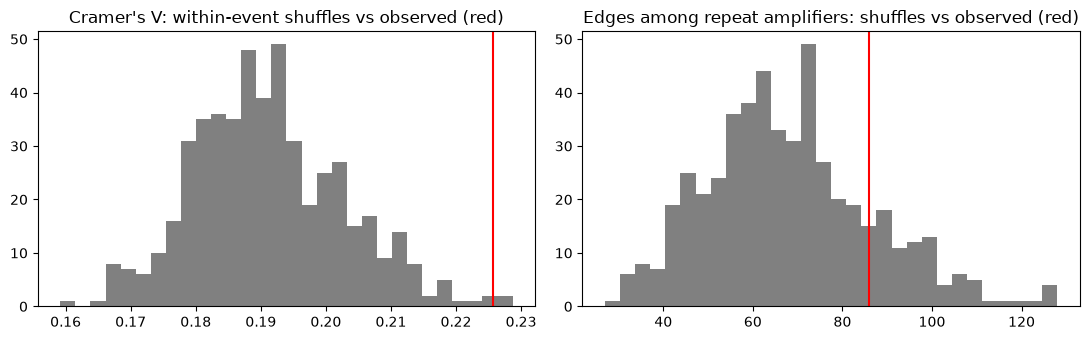

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(null_v, bins=30, color="gray"); ax[0].axvline(v_louvain, color="red")
ax[0].set_title("Cramer's V: within-event shuffles vs observed (red)")
ax[1].hist(null_edges, bins=30, color="gray"); ax[1].axvline(obs_edges, color="red")
ax[1].set_title("Edges among repeat amplifiers: shuffles vs observed (red)")
plt.tight_layout(); plt.show()

## 10. Sample for the D3 network graph

The API contract for `GET /api/cascades/network` is a list of nodes `{id, label, community, veracity}` and a list of edges `{source, target, weight}`. A browser cannot draw 48,000 users smoothly, so we export up to 300 users: the 30 best-connected users (by weighted degree) of each of the 10 largest communities. `id` is the pseudonymous user key, `veracity` is `misinformation` when the user took part in at least one false thread of the main events (Section 3) and `factual` otherwise. Edges are the reply links among the chosen users; users left without any edge are dropped so every node is drawn connected.

In [14]:
strength = pd.Series(dict(H.degree(weight="weight")))
user_false = known.groupby("user_key")["mis"].max().reindex(users).fillna(0)   # 1 if the user joined any false thread
threads_per_user = behaviour["threads"].astype(int)

chosen = []
for c in sizes.index[:10]:
    members = louvain_of.index[louvain_of == c]
    chosen.extend(strength[members].sort_values(ascending=False, kind="stable").index[:30].tolist())
chosen_set = set(chosen)
sample_edges = [{"source": u, "target": v, "weight": int(w)}
                for u, v, w in H.edges(data="weight") if u in chosen_set and v in chosen_set]
connected = {e["source"] for e in sample_edges} | {e["target"] for e in sample_edges}
nodes = [{"id": u, "label": f"{u} ({threads_per_user[u]} threads)", "community": int(louvain_of[u]),
          "veracity": "misinformation" if user_false[u] == 1 else "factual"} for u in chosen if u in connected]

network_sample = {"nodes": nodes, "edges": sample_edges}
with open(PROCESSED / "network_sample.json", "w", encoding="utf-8") as f:
    json.dump(network_sample, f)
print(f"nodes: {len(nodes)} (dropped {len(chosen) - len(nodes)} without edges) | edges: {len(sample_edges)} | "
      f"communities: {len({n['community'] for n in nodes})}")
print("misinformation nodes:", sum(n["veracity"] == "misinformation" for n in nodes))
print(nodes[0], sample_edges[0], sep="\n")

nodes: 224 (dropped 76 without edges) | edges: 349 | communities: 10
misinformation nodes: 68
{'id': 'u875', 'label': 'u875 (104 threads)', 'community': 0, 'veracity': 'factual'}
{'source': 'u875', 'target': 'u21510', 'weight': 2}


## 11. Appendix: narrative communities of cascades

The first version of this notebook grouped **cascades** by the text embedding of their source tweet, because the graph file had no users. That result still holds and is kept here in short form: Louvain on a 10-nearest-neighbour cosine graph of the 6,425 source-tweet embeddings, and the within-event permutation test of veracity assortativity. The embeddings exist only in the graph file (`gh release download pheme -D backend/data/pheme_political`), so this section is skipped when the file is missing.

In [15]:
import pickle


def knn_graph(E, k=10):
    dist, idx = NearestNeighbors(n_neighbors=k + 1, metric="cosine").fit(E).kneighbors(E)
    g = nx.Graph()
    g.add_nodes_from(range(len(E)))
    for i in range(len(E)):
        for d, j in zip(dist[i, 1:], idx[i, 1:]):
            j = int(j)
            if j != i:
                w = max(1.0 - float(d), 0.0)
                g.add_edge(i, j, weight=max(w, g[i][j]["weight"]) if g.has_edge(i, j) else w)
    return g


def edge_assortativity(a, u, v):
    x, y = np.concatenate([a[u], a[v]]), np.concatenate([a[v], a[u]])
    return float(np.corrcoef(x, y)[0, 1])


narrative = None
if GRAPH_FILE.exists():
    with open(GRAPH_FILE, "rb") as f:
        graphs = pickle.load(f)
    ids = np.array([str(g.graph["thread_id"]) for g in graphs])
    E = np.vstack([np.asarray(g.nodes[str(g.graph["thread_id"])]["text_embedding"], dtype=np.float32) for g in graphs])
    E = E / np.linalg.norm(E, axis=1, keepdims=True)
    del graphs
    Gc = knn_graph(E)
    comms = sorted(nx.community.louvain_communities(Gc, weight="weight", resolution=RESOLUTION, seed=SEED),
                   key=lambda c: (-len(c), min(c)))
    cas_lab = np.zeros(len(ids), dtype=int)
    for i, c in enumerate(comms):
        cas_lab[list(c)] = i
    q_cas = nx.community.modularity(Gc, comms, weight="weight", resolution=RESOLUTION)
    info = thread_info.loc[ids]
    ok = (info["main_event"] & info["mis"].notna()).to_numpy()
    a = info["mis"].to_numpy()
    edges = np.array([(u, v) for u, v in Gc.edges() if ok[u] and ok[v]])
    obs_assort = edge_assortativity(a, edges[:, 0], edges[:, 1])
    ok_idx = np.flatnonzero(ok)
    ev_groups = [ok_idx[pos] for pos in pd.Series(ok_idx).groupby(info["event"].to_numpy()[ok]).indices.values()]
    null_assort = []
    for _ in range(N_PERM):
        b = a.copy()
        for idx in ev_groups:
            b[idx] = rng.permutation(a[idx])
        null_assort.append(edge_assortativity(b, edges[:, 0], edges[:, 1]))
    p_assort = float((np.sum(np.array(null_assort) >= obs_assort) + 1) / (N_PERM + 1))
    narrative = {"cascade_ids": ids, "louvain": cas_lab, "communities": len(comms), "modularity": float(q_cas),
                 "ARI vs event": float(adjusted_rand_score(info["event"], cas_lab)),
                 "assortativity": obs_assort, "null_event_mean": float(np.mean(null_assort)), "p_vs_null_event": p_assort}
    print(f"narrative communities: {len(comms)}, Q = {q_cas:.3f}, ARI with event {narrative['ARI vs event']:.3f}")
    print(f"veracity assortativity {obs_assort:.3f} vs within-event shuffles {np.mean(null_assort):.3f} (p = {p_assort:.4f})")
else:
    print("graph file not found; appendix skipped:", GRAPH_FILE)

narrative communities: 23, Q = 0.843, ARI with event 0.533
veracity assortativity 0.496 vs within-event shuffles 0.048 (p = 0.0020)


## 12. Save the results

`community_clusters.joblib` stores both user groupings for every user in the component (keyed by the pseudonymous user key), the fitted K-Means with its scaler, the settings, the community profiles, the repeat amplifiers and, when the appendix ran, the narrative communities of cascades.

In [16]:
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.ndarray):
        return clean(o.tolist())
    return o


versions = {"sklearn": sklearn.__version__, "networkx": nx.__version__, "numpy": np.__version__, "pandas": pd.__version__}
kmeans_model = Pipeline([("scale", scaler), ("kmeans", km)])
amplifier_keys = np.array(users)[amp]

artifact = {
    "unit_of_analysis": "user (pseudonymous key from pheme_interactions.csv.gz)",
    "user_keys": np.array(users),
    "louvain": louvain,
    "kmeans": kmeans,
    "kmeans_model": kmeans_model,
    "kmeans_label_map": {int(k): int(v) for k, v in remap.items()},
    "kmeans_features": LOG_COLS + ["verified"],
    "settings": {"louvain_resolution": RESOLUTION, "best_k": best_k, "seed": SEED, "n_perm": N_PERM,
                 "min_false_threads": MIN_FALSE_THREADS},
    "modularity": Q,
    "louvain_profile": louvain_profile.reset_index(names="community").to_dict(orient="records"),
    "kmeans_profile": kmeans_profile.reset_index(names="cluster").to_dict(orient="records"),
    "repeat_amplifiers": amplifier_keys,
    "narrative_communities": narrative,
    "versions": versions,
}
joblib.dump(artifact, MODELS / "community_clusters.joblib")

report = {
    "unit_of_analysis": artifact["unit_of_analysis"],
    "graph": {"users_with_links": G.number_of_nodes(), "edges": G.number_of_edges(), "components": len(components),
              "largest_component_users": H.number_of_nodes(), "largest_component_edges": H.number_of_edges()},
    "participations_known_main_events": len(known), "false_share_overall": overall_false,
    "louvain": {"resolution": RESOLUTION, "communities": n_comm, "modularity": Q,
                "resolution_scan": res_table.to_dict(orient="records")},
    "kmeans": {"best_k": best_k, "scan": k_table.to_dict(orient="records"),
               "roles": roles.reset_index().to_dict(orient="records")},
    "agreement": compare.to_dict(orient="index"),
    "concentration": {"cramers_v": {"louvain": v_louvain, "kmeans": v_kmeans, "event": v_event},
                      "null_event_mean": float(null_v.mean()), "null_event_max": float(null_v.max()), "p_vs_null_event": p_v},
    "repeat_amplifiers": {"min_false_threads": MIN_FALSE_THREADS, "count": obs_amp, "null_mean_count": float(null_amp.mean()), "p_count": p_amp,
                          "edges_among": obs_edges, "null_mean_edges": float(null_edges.mean()),
                          "null_max_edges": int(null_edges.max()), "p_edges": p_edges,
                          "top5_share_of_amplifiers": obs_top5, "null_mean_top5_share": float(null_top5.mean()), "p_top5": p_top5, "top5_share_of_users": float(top5_user_share)},
    "top_communities_by_false_share": louvain_shown.head(5).reset_index(names="community").to_dict(orient="records"),
    "network_sample": {"nodes": len(nodes), "edges": len(sample_edges)},
    "narrative_appendix": None if narrative is None else {k: v for k, v in narrative.items() if k not in ("cascade_ids", "louvain")},
    "versions": versions, "seed": SEED,
}
with open(REPORTS / "community_metrics.json", "w", encoding="utf-8") as f:
    json.dump(clean(report), f, indent=2)
print("saved:", MODELS / "community_clusters.joblib")
print("saved:", PROCESSED / "network_sample.json")
print("saved:", REPORTS / "community_metrics.json")

saved: /Users/phaman/Documents/COS30048 - Inno/inno/backend/models/community_clusters.joblib
saved: /Users/phaman/Documents/COS30048 - Inno/inno/backend/data/processed/network_sample.json
saved: /Users/phaman/Documents/COS30048 - Inno/inno/backend/reports/community_metrics.json


In [17]:
# Reload test
art = joblib.load(MODELS / "community_clusters.joblib")
print(len(art["user_keys"]), "users | settings:", art["settings"])
pred = [art["kmeans_label_map"][int(c)] for c in art["kmeans_model"].predict(X[:3])]
print("K-Means role of the first 3 users:", pred, "(saved:", art["kmeans"][:3].tolist(), ")")

47833 users | settings: {'louvain_resolution': 1.0, 'best_k': 4, 'seed': 42, 'n_perm': 500, 'min_false_threads': 3}
K-Means role of the first 3 users: [2, 0, 1] (saved: [2, 0, 1] )


### Numbers quoted in the Discussion

Every number in the Discussion below is printed here or in an earlier cell, so it cannot go stale on a re-run.

In [18]:
top = louvain_shown.head(3)
facts = {
    "share of users in the component living in communities >= MIN_USERS": round(float(sizes[sizes >= MIN_USERS].sum() / len(users)), 3),
    "top 3 communities by false share (users, false share, top event, purity)":
        [(int(c), int(r.users), round(float(r.false_share), 3), r.top_event, round(float(r.event_purity), 3)) for c, r in top.iterrows()],
    "false share range over communities >= MIN_USERS": [round(float(louvain_shown["false_share"].min()), 3),
                                                        round(float(louvain_shown["false_share"].max()), 3)],
    "median event purity of communities >= MIN_USERS": round(float(louvain_shown["event_purity"].median()), 3),
    "unverified rumours left out of every rate": int((thread_info["veracity"] == "unverified").sum()),
}
for k, v in facts.items():
    print(f"{k}: {v}")

share of users in the component living in communities >= MIN_USERS: 0.67
top 3 communities by false share (users, false share, top event, purity): [(20, 528, 0.179, 'sydneysiege', 0.651), (12, 650, 0.17, 'charliehebdo', 0.434), (1, 1248, 0.14, 'sydneysiege', 0.384)]
false share range over communities >= MIN_USERS: [0.002, 0.179]
median event purity of communities >= MIN_USERS: 0.724
unverified rumours left out of every rate: 697


## 13. Discussion

**1. The user network exists.** 50,041 of the 50,593 accounts in PHEME have at least one reply link, and 47,833 of them (95.6%) form one connected network with 61,942 links. Users who join several threads tie the conversations of different threads, and even of different events, together. This is the user-level interaction graph FR3 asks for, which the graph file could not provide.

**2. Louvain: communities of users who talk to each other.** With the default resolution Louvain finds 143 communities with modularity Q = 0.871; the 51 communities with at least 300 users hold 67% of the users. The communities mostly stay inside one news event (median event purity 72% for those 51 communities), but they split each event into many groups, so the agreement with the event is low (ARI 0.043, NMI 0.230). A lower resolution of 0.5 gives 85 communities that follow the events a little more (ARI 0.138). Part of the high modularity comes from the shape of reply data: the graph is sparse and tree-like, which makes communities easy to separate, so Q should not be read as proof of closed echo chambers by itself.

**3. K-Means: behavioural roles, not conversation groups.** On the behaviour features, K-Means picks k = 4 (silhouette 0.556) and finds four clear roles: 39,235 casual repliers (median one thread, one reply, about 290 followers), 6,032 active repliers (median two threads, five replies sent), 1,344 unverified thread starters and 1,222 verified thread starters (median about 34,000 followers). The roles are unrelated to the Louvain communities (ARI 0.001) and to the event (ARI -0.004): every conversation group has casual users and a few accounts that start threads. The roles also say almost nothing about veracity (Cramer's V 0.020; false share 6.5%, 5.9%, 6.3% and 8.1%).

**4. Do false rumours concentrate in some communities?** Yes, but the effect is small. Over all participations, 6.4% are in false threads, and the communities with at least 300 users range from 0.2% to 17.9%. The most false-heavy are community 20 (528 users, 17.9% false, mostly Sydney siege), community 12 (650 users, 17.0%, Charlie Hebdo) and community 1 (1,248 users, 14.0%, Sydney siege). Cramer's V between community and "false" is 0.226, against 0.199 for the event alone. When the veracity labels are shuffled between threads of the same event, V averages 0.191 and reaches 0.229 at most in 500 shuffles (p = 0.008). So who talks to whom carries some information about false-rumour participation beyond the event, but most of the link is still explained by the event.

**5. Is there coordinated amplification?** We found no evidence of it. 54 users took part in three or more false threads, a little more than within-event shuffles give (mean 44.5, p = 0.048): some users do return to false threads more often than chance. But these repeat amplifiers are not linked to each other more than chance (86 links among them against 68.1 on average in the shuffles, p = 0.17), and they are not concentrated in a few communities either (the 5 communities with the most of them hold 37%, against 35% in the shuffles, p = 0.32). Busy users are connected to each other in any case, and the shuffles show that this explains the links. Within PHEME, false rumours look like they spread through ordinary conversation, not through a coordinated group.

**6. Narrative communities (appendix).** The earlier cascade-level analysis still holds: 23 narrative communities (Q = 0.843) that largely follow the event (ARI 0.533), and veracity assortativity of 0.496 against 0.048 under within-event shuffles (p = 0.002). Two cascades that tell the same story tend to share a veracity, partly because PHEME labels rumours about one story with one label. Both views are useful: narratives say which stories are false, user communities say where people discuss them.

**7. What the dashboard should say.** The Network page now shows **users** (pseudonymous keys such as `u875`), not cascades. Each node is coloured by its Louvain community, and `misinformation` marks users who took part in at least one false thread of the main events (68 of the 224 exported users). The page should describe the groups as interaction communities with a modest tendency to concentrate false rumours, and should not claim coordinated campaigns, because Section 9 does not support that.

**8. Limitations.** PHEME has replies only, not retweets or follows, so the links are conversations, not the full audience. User ids are pseudonymous, so no account can be checked by hand. Only 6.4% of the usable participations are false, the 697 unverified rumours and two almost-all-false events are left out of every rate, and the data cover a few events from 2014-2015, so the findings may not carry over to other events or platforms.